# Chapter 5 — Linear Models and Regularization
**Buku:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt, 2025)
**Cakupan notebook:** reproduksi kode + ringkasan + penjelasan teori Chapter 5 (tanpa bagian *Hands-on/Practical exercises*)



## Ringkasan Chapter
Chapter 5 membahas **model linear** dan **regularisasi**. Dimulai dari regresi linear (OLS), lalu **Ridge** (penalti L2), **Lasso** (penalti L1), dan **ElasticNet** (gabungan keduanya) untuk mencegah overfitting. Dibahas juga teori regularisasi (kompleksitas model dan *bias-variance trade-off*), serta perluasan regresi linear ke hubungan non-linear dengan **polynomial regression** dan **spline** (`SplineTransformer`).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.8.0


## 1. Introduction to Linear Models
Model linear adalah tulang punggung banyak teknik pemodelan prediktif dan memberi cara langsung untuk memahami hubungan antar variabel. Regresi linear mencari persamaan garis (atau hyperplane) yang menghubungkan fitur dengan target. Bentuk paling sederhana, **Ordinary Least Squares (OLS)**, meminimalkan jumlah kuadrat selisih antara nilai sebenarnya dan prediksi.

### Getting ready: dataset sintetis
`make_regression` membuat dataset regresi sintetis: **1000 sampel, 100 fitur** (hanya 10 yang informatif), dengan *noise*. Lalu dibuat **multikolinearitas** (setengah fitur dibuat berkorelasi dengan setengah lainnya) dan target diskalakan.

> **Perbaikan reproduksi:** langkah multikolinearitas di buku memakai `np.random.normal` tanpa seed, sehingga angka Anda berbeda tiap dijalankan dan tidak akan persis sama dengan gambar di buku. Saya tambahkan `np.random.seed(123)`.

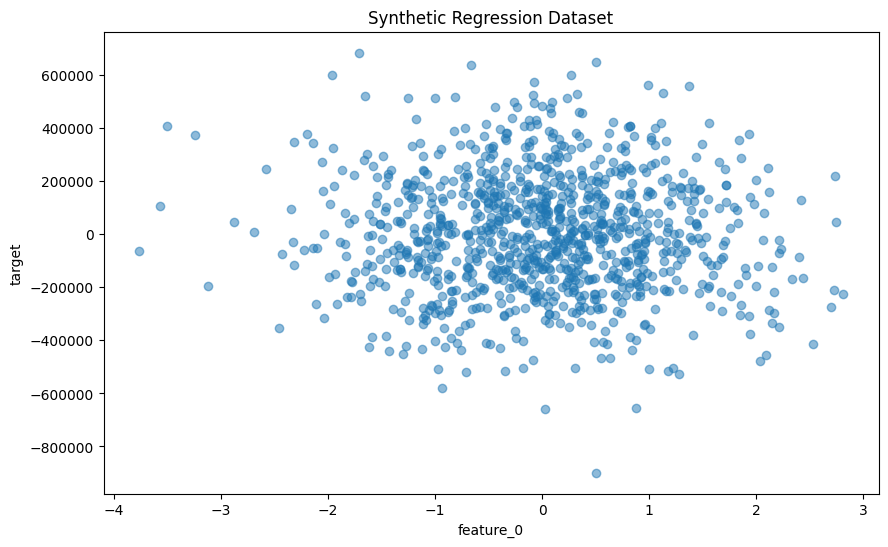

In [2]:
# [Dari buku] Dataset sintetis dengan multikolinearitas
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=20, random_state=123)

# Tambahkan multikolinearitas: fitur 50-99 dibuat berkorelasi dengan fitur 0-49
np.random.seed(123)   # [tambahan saya] agar reproducible
for i in range(50, 100):
    X[:, i] = X[:, i - 50] + np.random.normal(0, 0.1, size=1000)

feature_names = [f"feature_{i}" for i in range(100)]

# Ambil satu fitur untuk visualisasi 2D
X_plot = X[:, 0].reshape(-1, 1)

# Skala target dan tambahkan sedikit non-linearitas
y = y * 1000
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10)

df = pd.DataFrame(X, columns=feature_names)
df["target"] = y
df_plot = pd.DataFrame({"feature_0": X_plot.ravel(), "target": y})

plt.figure(figsize=(10, 6))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel("feature_0")
plt.ylabel("target")
plt.title("Synthetic Regression Dataset")
plt.show()

In [3]:
# [Tambahan] Verifikasi multikolinearitas dan skala target
print("Korelasi feature_0 vs feature_50:", round(np.corrcoef(X[:, 0], X[:, 50])[0, 1], 4))
print("Target: mean =", round(y.mean(), 1), "| std =", round(y.std(), 1), "| min/max =", round(y.min()), "/", round(y.max()))
print("Std dari suku sin+exp yang ditambahkan:", round((np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10)).std(), 1))

Korelasi feature_0 vs feature_50: 0.9952
Target: mean = 1229.2 | std = 223820.6 | min/max = -898455 / 683148
Std dari suku sin+exp yang ditambahkan: 98.3


**Interpretasi:** plot hanya menampilkan 1 dari 100 fitur sehingga tampak acak. Dua catatan dari sel verifikasi: (1) `feature_50` hampir identik dengan `feature_0` (korelasi mendekati 1), yaitu multikolinearitas yang sengaja dibuat; (2) karena target dikalikan 1000, suku `sin` dan `exp` yang dimaksudkan sebagai "non-linearitas" hanya berkontribusi sangat kecil dibanding total variasi target, jadi data ini praktis **hampir linear**.

### How to do it…
Bagi data menjadi latih dan uji, latih `LinearRegression`, lalu evaluasi dengan **MSE** dan **R²**.

In [4]:
# [Dari buku] Split, fit LinearRegression, evaluasi
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Squared Error: 46550591070.53
R-squared: 0.06


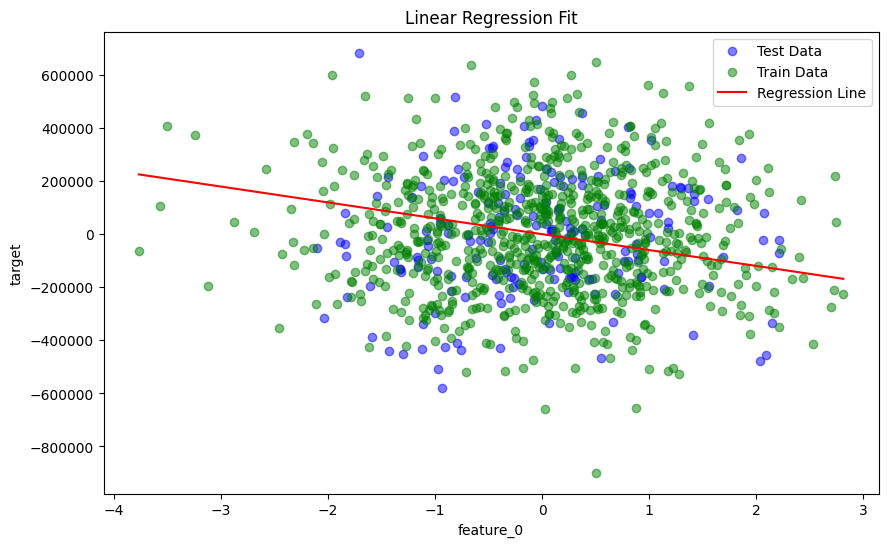

In [5]:
# [Dari buku] Visualisasi garis regresi (memakai feature_0, fitur lain diset 0)
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color="blue", alpha=0.5, label="Test Data")
plt.scatter(X_train[:, 0], y_train, color="green", alpha=0.5, label="Train Data")

X_line = np.linspace(df["feature_0"].min(), df["feature_0"].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()   # set feature_0, sisanya 0
y_line = linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names))

plt.plot(X_line, y_line, color="red", label="Regression Line")
plt.xlabel("feature_0")
plt.ylabel("target")
plt.title("Linear Regression Fit")
plt.legend()
plt.show()

**Hasil dan catatan penting:** MSE ≈ 4,66×10¹⁰ dan R² ≈ **0,06**: model hanya menjelaskan sekitar 6% variasi target (di buku R² juga rendah, ≈0,09 pada Figure 5.3). Ini bukan kesalahan kode Anda. `make_regression` menaruh fitur informatif di kolom acak. Dengan seed ini, **7 dari 10 fitur informatif berada di kolom 50–99**, dan loop multikolinearitas **menimpa** kolom-kolom itu *setelah* target dibuat. Informasi tentang target hilang dari `X`, jadi model mana pun tidak bisa memprediksi dengan baik. Ini kelemahan dataset contoh buku yang perlu diketahui agar tidak menyimpulkan bahwa "regresi linear itu buruk".

**Interpretasi:** garis merah adalah prediksi model ketika `feature_0` divariasikan dan 99 fitur lain dibuat 0. Ini hanyalah "irisan" 1 dimensi dari model 100 dimensi, sehingga garis tidak harus melewati awan titik secara visual (titik-titik dipengaruhi 99 fitur lain).

### How it works…
Regresi linear memodelkan hubungan linear antara target (variabel dependen) dan satu atau lebih fitur (variabel independen):
$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p + \epsilon$$
dengan $y$ nilai target, $\beta_0$ intersep, $\beta_j$ koefisien fitur ke-$j$, $x_j$ nilai fitur, dan $\epsilon$ galat. OLS memilih $\beta$ yang meminimalkan $\sum_i (y_i - \hat{y}_i)^2$.

**Metrik evaluasi:**
- **MSE** $= \frac{1}{n}\sum_i (y_i - \hat{y}_i)^2$: rata-rata kuadrat galat (satuan target dikuadratkan; makin kecil makin baik).
- **R²** $= 1 - \dfrac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$: proporsi variasi target yang dijelaskan model (1 = sempurna).

### There's more…
Setelah nyaman dengan regresi linear dasar: **regularisasi** (Ridge/Lasso) mencegah overfitting dengan menghukum koefisien besar, dan **regresi logistik** memperluas model linear untuk memprediksi probabilitas kelas (dibahas di bab berikutnya buku).

## 2. Ridge and Lasso Regression
**Regularisasi** mencegah overfitting dengan menambahkan **penalti** pada fungsi loss yang "menghukum" model yang terlalu kompleks. `Ridge` dan `Lasso` mirip `LinearRegression` tetapi punya parameter tambahan **`alpha`** yang mengatur kekuatan regularisasi (alpha lebih besar → penalti lebih kuat). Dataset yang sama dipakai.

### How to do it…

In [6]:
# [Dari buku] Fit Ridge dan Lasso
from sklearn.linear_model import Ridge, Lasso

ridge_model = Ridge(alpha=1.0)   # alpha mengatur kekuatan regularisasi
ridge_model.fit(X_train, y_train)

lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)
y_pred_linear = linear_model.predict(X_test)

In [7]:
# [Dari buku, dengan perbaikan] Tabel perbandingan metrik.
# Buku memformat angka menjadi STRING lalu nanti menggabungkan & meng-sort baris ElasticNet (float).
# Di lingkungan saya (pandas 3.0.2) urutan itu menghasilkan TypeError (str vs float); Figure 5.5 buku tampil normal, kemungkinan versi pandas berbeda.
# Di sini angka dibiarkan numerik; pemformatan hanya saat ditampilkan.
metrics = {
    "Model": ["Ridge Regression", "Lasso Regression", "Linear Regression"],
    "Mean Squared Error": [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear),
    ],
    "R-squared": [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear),
    ],
}
metrics_df = pd.DataFrame(metrics).sort_values("Mean Squared Error", ascending=True).reset_index(drop=True)
fmt = {"Mean Squared Error": "{:.2f}", "R-squared": "{:.4f}"}
display(metrics_df.style.format(fmt))

,Model,Mean Squared Error,R-squared
0,Ridge Regression,45341091794.40,0.0891
1,Lasso Regression,46377111017.93,0.0683
2,Linear Regression,46550591070.53,0.0648


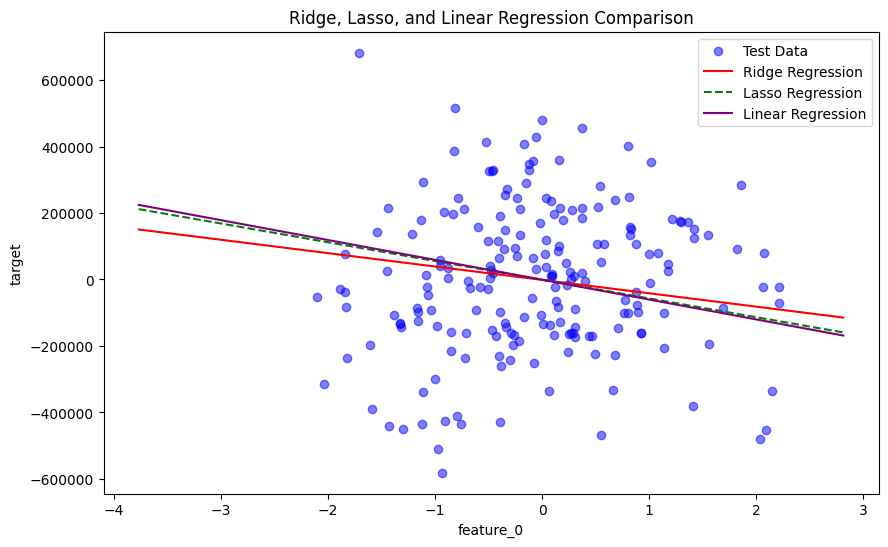

In [8]:
# [Dari buku] Visualisasi ketiga model (feature_0)
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color="blue", alpha=0.5, label="Test Data")

X_line = np.linspace(df["feature_0"].min(), df["feature_0"].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
X_line_df = pd.DataFrame(X_line_full, columns=feature_names)

plt.plot(X_line, ridge_model.predict(X_line_df), color="red", label="Ridge Regression")
plt.plot(X_line, lasso_model.predict(X_line_df), color="green", linestyle="--", label="Lasso Regression")
plt.plot(X_line, linear_model.predict(X_line_df), color="purple", label="Linear Regression")
plt.xlabel("feature_0")
plt.ylabel("target")
plt.title("Ridge, Lasso, and Linear Regression Comparison")
plt.legend()
plt.show()

In [9]:
# [Tambahan] Apa yang sebenarnya dilakukan regularisasi pada koefisien?
coefs = pd.DataFrame({
    "Linear": linear_model.coef_, "Ridge": ridge_model.coef_, "Lasso": lasso_model.coef_,
}, index=feature_names)
print("Jumlah koefisien = 0 (dari 100):", (coefs == 0).sum().to_dict())
print("Norma L2 koefisien:", coefs.apply(lambda c: np.linalg.norm(c)).round(1).to_dict())
print("Koefisien |terbesar|:", coefs.abs().max().round(1).to_dict())

Jumlah koefisien = 0 (dari 100): {'Linear': 0, 'Ridge': 0, 'Lasso': 0}
Norma L2 koefisien: {'Linear': 686614.2, 'Ridge': 522352.3, 'Lasso': 668007.2}
Koefisien |terbesar|: {'Linear': 168982.7, 'Ridge': 122267.0, 'Lasso': 165217.2}


**Hasil pada eksekusi ini (MSE uji / R²):** Ridge 4,534×10¹⁰ / 0,089; Lasso 4,638×10¹⁰ / 0,068; Linear 4,655×10¹⁰ / 0,065. Urutannya sama dengan Figure 5.3 buku (Ridge terbaik, lalu Lasso, lalu Linear), walaupun angka persisnya berbeda (buku: 4,44 / 4,54 / 4,55×10¹⁰) karena noise multikolinearitas di buku tidak diberi seed. Selisihnya kecil (Ridge hanya ≈2,6% lebih baik daripada OLS) dan semua model masih menjelaskan <10% variasi target karena alasan yang dijelaskan di atas.

Sel koefisien menunjukkan efek regularisasi: Ridge mengecilkan norma koefisien (≈522 ribu vs ≈687 ribu pada OLS). Lasso dengan `alpha=10` **tidak menjadikan satu pun koefisien tepat 0**: penalti itu terlalu kecil dibanding skala koefisien yang mencapai ratusan ribu, sehingga Lasso di sini hampir sama dengan OLS.

> **Catatan:** pernyataan buku bahwa Ridge dan Lasso "lebih baik" daripada regresi linear biasa benar secara urutan pada hasil ini, tetapi selisihnya kecil. Bacalah lewat angka pada tabel, bukan diasumsikan.

### How it works…
Ridge dan Lasso sama-sama **menyusutkan koefisien** dengan menambahkan penalti pada loss OLS:

- **Ridge (penalti L2):** $\;\text{Loss} = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p}\beta_j^2$
  Mengecilkan koefisien besar tanpa menjadikannya tepat 0, sehingga **semua fitur tetap dipakai**.
- **Lasso (penalti L1):** $\;\text{Loss} = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^{p}\lvert\beta_j\rvert$
  Selain mencegah overfitting, juga melakukan **seleksi fitur** karena sebagian koefisien menjadi tepat 0.

**Kapan dipakai?** Ridge bila ingin mempertahankan semua fitur dan mengurangi dampaknya; Lasso bila dicurigai banyak fitur tidak relevan/redundan.

> **Catatan teknis (dari dokumentasi scikit-learn):** rumus di atas adalah bentuk konseptual dari buku. Implementasi scikit-learn sedikit berbeda dalam skala: `Ridge` meminimalkan $\lVert y - Xw\rVert_2^2 + \alpha\lVert w\rVert_2^2$, tetapi `Lasso` meminimalkan $\frac{1}{2n}\lVert y - Xw\rVert_2^2 + \alpha\lVert w\rVert_1$ (ada faktor $\frac{1}{2n}$). Karena itu nilai `alpha` yang sama tidak setara antar kelas.

## 3. ElasticNet and Regularization
**ElasticNet** menggabungkan penalti Ridge dan Lasso. Selain `alpha` (kekuatan regularisasi total), ada **`l1_ratio`** yang mengatur campuran: `l1_ratio=1` → seperti Lasso, `l1_ratio=0` → seperti Ridge. Berguna bila ada fitur-fitur yang berkorelasi tinggi bersama fitur yang tidak berkorelasi.

### How to do it…
Buku memvisualisasikan **coefficient path** (nilai koefisien tiap fitur vs kekuatan regularisasi `alpha`) untuk 7 nilai `alpha` × 5 nilai `l1_ratio` (35 model).

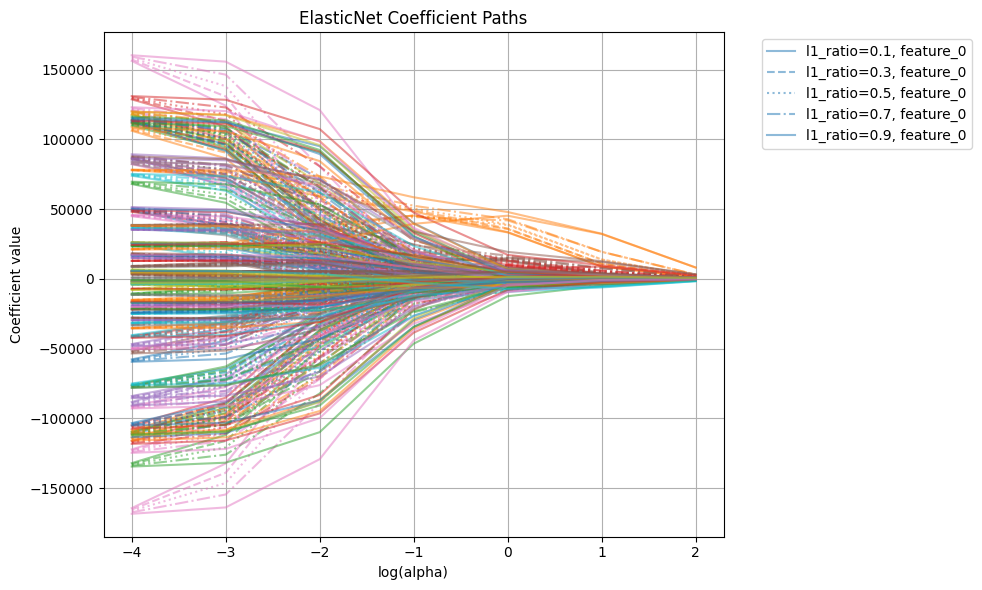

In [10]:
# [Dari buku] ElasticNet coefficient paths
from sklearn.linear_model import ElasticNet

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

coef_paths = []
labels = []

plt.figure(figsize=(10, 6))
for l1_ratio in l1_ratios:
    coefs_l = []
    for alpha in alphas:
        elastic_model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=123, max_iter=10000, tol=1e-4)
        elastic_model.fit(X_train, y_train)
        coefs_l.append(elastic_model.coef_)
    coef_paths.append(np.array(coefs_l))

    for feature_idx in range(X_train.shape[1]):
        plt.plot(
            np.log10(alphas), np.array(coefs_l)[:, feature_idx],
            label=f"l1_ratio={l1_ratio}, feature_{feature_idx}" if feature_idx == 0 else "",
            alpha=0.5,
            linestyle=["solid", "dashed", "dotted", "dashdot", "-"][l1_ratios.index(l1_ratio)],
        )

plt.xlabel("log(alpha)")
plt.ylabel("Coefficient value")
plt.title("ElasticNet Coefficient Paths")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

**Cara membaca coefficient path:** sumbu-x = $\log_{10}(\alpha)$ (regularisasi makin kuat ke kanan), sumbu-y = nilai koefisien. Tiap garis adalah satu fitur dan gaya garis menunjukkan `l1_ratio`. Secara umum, saat $\alpha$ naik koefisien mengecil menuju 0, dan koefisien yang tepat 0 berarti fitur "dibuang". `l1_ratio` kecil (0,1) berperilaku mirip Ridge (menyusutkan), `l1_ratio` besar (0,9) mirip Lasso (menghapus fitur). Fitur penting bertahan lebih lama dari penyusutan.

> Buku mengakui plot ini sulit dibaca karena ada 100 fitur. Pada kasus ini skala koefisien juga sangat besar (target dikali 1000), jadi sebagian besar garis tampak datar sampai $\alpha$ sangat besar. Sel [Tambahan] di bawah menunjukkan efek yang sama dengan lebih jelas.

In [11]:
# [Dari buku] ElasticNet dengan alpha=1, l1_ratio=0.5, lalu masukkan ke tabel metrik
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4)
elastic_model.fit(X_train, y_train)

elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

new_row = pd.DataFrame({"Model": ["ElasticNet Regression"], "Mean Squared Error": [elastic_mse], "R-squared": [elastic_r2]})

# Hapus entri ElasticNet lama (bila sel dijalankan ulang), gabungkan, urutkan menurut MSE
metrics_df = metrics_df[~metrics_df["Model"].str.contains("ElasticNet")]
metrics_df = pd.concat([metrics_df, new_row], ignore_index=True)
metrics_df = metrics_df.sort_values("Mean Squared Error", ascending=True).reset_index(drop=True)
display(metrics_df.style.format(fmt))

,Model,Mean Squared Error,R-squared
0,ElasticNet Regression,42616635365.79,0.1438
1,Ridge Regression,45341091794.40,0.0891
2,Lasso Regression,46377111017.93,0.0683
3,Linear Regression,46550591070.53,0.0648


**Hasil:** ElasticNet memperoleh MSE 4,262×10¹⁰ dan R² 0,144 (buku: 4,265×10¹⁰ dan 0,14). Ini terbaik di antara keempat model, sesuai klaim buku. Tetapi *mengapa*? Sel berikut menunjukkan bahwa penyebab utamanya adalah **skala `alpha`**, bukan sifat "hibrida" L1+L2.

In [12]:
# [Tambahan] Apakah keunggulan ElasticNet berasal dari "campuran" L1+L2, atau dari kekuatan penalti?
# Mengalikan loss ElasticNet dengan 2n: penalti L2 efektifnya = n * alpha * (1 - l1_ratio) dalam skala Ridge (yang tanpa faktor 1/(2n)).
n_train = X_train.shape[0]
equiv_ridge_alpha = n_train * 1.0 * (1 - 0.5)
print("alpha Ridge yang setara dengan komponen L2 ElasticNet(alpha=1, l1_ratio=0.5):", equiv_ridge_alpha)

cmp_rows = [
    ("Ridge(alpha=1)  [dari buku]", Ridge(alpha=1.0)),
    (f"Ridge(alpha={equiv_ridge_alpha:.0f})", Ridge(alpha=equiv_ridge_alpha)),
    ("ElasticNet(alpha=1, l1_ratio=0.5)", ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4)),
]
out = []
for name, m in cmp_rows:
    m.fit(X_train, y_train)
    out.append({"Model": name, "MSE uji": mean_squared_error(y_test, m.predict(X_test))})
display(pd.DataFrame(out).style.format({"MSE uji": "{:.0f}"}))

alpha Ridge yang setara dengan komponen L2 ElasticNet(alpha=1, l1_ratio=0.5): 400.0


,Model,MSE uji
0,Ridge(alpha=1) [dari buku],45341091794
1,Ridge(alpha=400),42616914345
2,"ElasticNet(alpha=1, l1_ratio=0.5)",42616635366


**Interpretasi:** `Ridge(alpha=400)` menghasilkan MSE uji hampir **identik** dengan ElasticNet (≈4,2617×10¹⁰ untuk keduanya), sedangkan `Ridge(alpha=1)` yang dipakai buku jauh lebih lemah (≈4,534×10¹⁰). Jadi pada tabel buku, ElasticNet menang terutama karena penalti L2 efektifnya ≈400 kali lebih kuat daripada Ridge `alpha=1` (akibat perbedaan skala loss scikit-learn), bukan karena kombinasi L1+L2 itu sendiri. Pelajaran praktisnya: membandingkan model dengan nilai `alpha` default tanpa menalanya (*tuning*) bisa menyesatkan. Bandingkan model dengan `alpha` yang masing-masing sudah dituning lewat cross-validation.

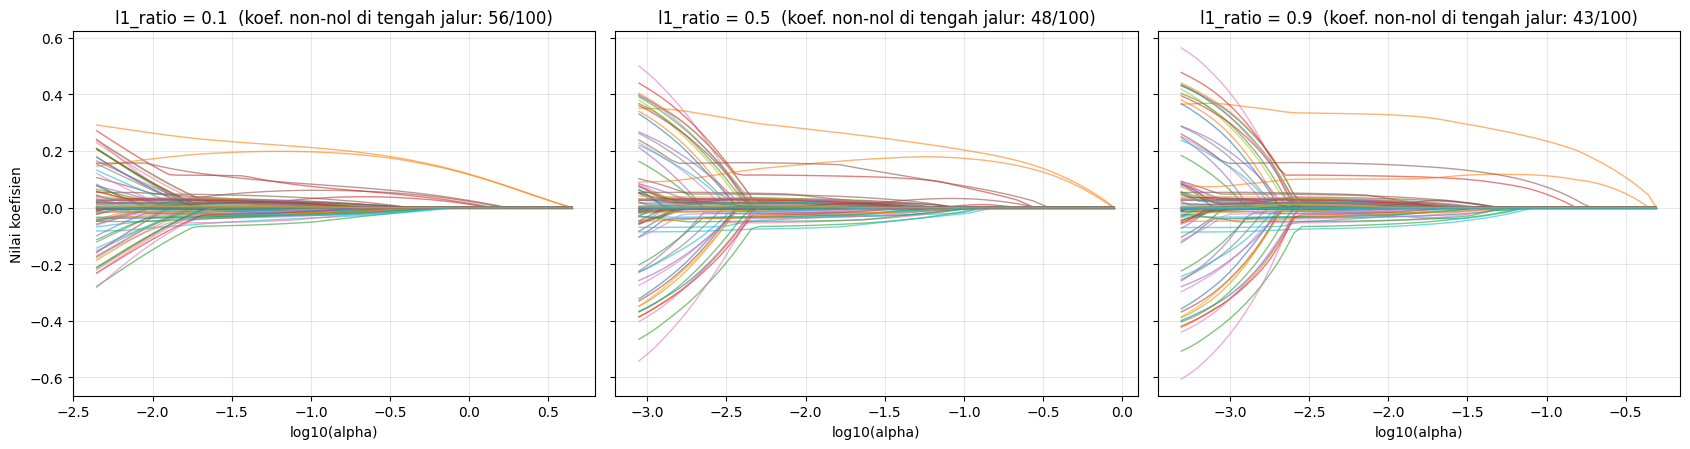

In [13]:
# [Tambahan] Coefficient path yang lebih jelas: fitur DAN target distandarisasi, alpha pada skala yang sesuai
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import enet_path

Xs = StandardScaler().fit_transform(X_train)
ys = (y_train - y_train.mean()) / y_train.std()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
for ax, rho in zip(axes, [0.1, 0.5, 0.9]):
    alphas_path, coefs_path, _ = enet_path(Xs, ys, l1_ratio=rho, n_alphas=60)
    for j in range(coefs_path.shape[0]):
        ax.plot(np.log10(alphas_path), coefs_path[j], alpha=0.6, linewidth=1)
    nonzero_at_mid = int((coefs_path[:, len(alphas_path) // 2] != 0).sum())
    ax.set_title(f"l1_ratio = {rho}  (koef. non-nol di tengah jalur: {nonzero_at_mid}/100)")
    ax.set_xlabel("log10(alpha)"); ax.grid(True, alpha=0.3)
axes[0].set_ylabel("Nilai koefisien")
plt.tight_layout(); plt.show()

**Interpretasi:** setelah fitur dan target distandarisasi, efek regularisasi terlihat jelas. Di sisi kiri ($\alpha$ kecil) koefisien besar dan banyak yang aktif; seiring $\alpha$ naik, koefisien menyusut dan menjadi 0. Perhatikan bahwa pada `l1_ratio` lebih tinggi (lebih mirip Lasso), lebih banyak koefisien menjadi tepat 0 pada $\alpha$ yang sama: di tengah rentang alpha, jumlah koefisien non-nol adalah sekitar 56 (`l1_ratio=0,1`), 48 (`0,5`), dan 43 (`0,9`) dari 100 (angka juga tertera pada judul tiap panel). Hanya sekitar 10 fitur yang benar-benar informatif, sehingga fitur-fitur itulah yang bertahan paling lama dari penyusutan.

### How it works…
ElasticNet menggabungkan penalti L1 (Lasso) dan L2 (Ridge). Buku menuliskan:
$$\text{Loss} = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \alpha\Big(\lambda_1\sum_{j=1}^{p}\lvert\beta_j\rvert + \lambda_2\sum_{j=1}^{p}\beta_j^2\Big)$$
dengan $\alpha$ kekuatan regularisasi total, $\lambda_1$ bobot penalti L1, dan $\lambda_2$ bobot penalti L2.

> **Koreksi implementasi:** scikit-learn tidak memakai $\lambda_1,\lambda_2$ secara terpisah, melainkan parameter **`l1_ratio`** $=\rho$:
> $$\frac{1}{2n}\lVert y - Xw\rVert_2^2 + \alpha\rho\lVert w\rVert_1 + \frac{\alpha(1-\rho)}{2}\lVert w\rVert_2^2$$
> Jadi `l1_ratio=1` setara Lasso, `l1_ratio=0` mendekati Ridge, dan nilai di antaranya adalah campuran keduanya.

**Keunggulan:** ElasticNet dapat melakukan seleksi fitur otomatis seperti Lasso, sekaligus lebih stabil pada fitur berkorelasi (sifat L2). Ini berguna pada data berdimensi tinggi.

## 4. Regularization Theory and Practice
Regularisasi hampir selalu dipakai pada aplikasi ML nyata. Ia mencegah **overfitting** dan meningkatkan **generalisasi** (kemampuan model berkinerja baik pada data baru) dengan menambahkan **penalti** pada fungsi loss selama pelatihan, sehingga model tidak terlalu kompleks atau terlalu bergantung pada fitur tertentu. Inti idenya adalah menyeimbangkan **kompleksitas model** dan **kecocokan terhadap data**: tanpa regularisasi model bisa hampir sempurna pada data latih tetapi buruk pada data baru.

**Kompleksitas model** adalah kapasitas model untuk mencocokkan beragam fungsi. Model yang terlalu kompleks menangkap pola rumit (termasuk noise) dan gagal menggeneralisasi.

**Jenis regularisasi:**
| Jenis | Penalti | Efek |
|---|---|---|
| **L1 (Lasso)** | jumlah nilai absolut koefisien | Model *sparse*: sebagian koefisien tepat 0 (seleksi fitur) |
| **L2 (Ridge)** | jumlah kuadrat koefisien | Koefisien besar dikecilkan, tidak menjadi 0; semua fitur tetap berkontribusi |
| **ElasticNet** | gabungan L1 + L2 | Seleksi fitur sekaligus penyusutan; baik untuk fitur berkorelasi atau ketika fitur lebih banyak daripada sampel |

### Bias-variance trade-off
- Regularisasi umumnya **menaikkan bias sedikit** (model dibatasi) tetapi **menurunkan variansi** secara signifikan (prediksi kurang sensitif terhadap fluktuasi data latih).
- Tujuannya menemukan tingkat regularisasi optimal yang meminimalkan **galat prediksi total pada data baru**.

### There's more…
Selain Lasso dan Ridge: *group Lasso* (seleksi fitur berkelompok) dan regresi Bayesian (prior pada koefisien).

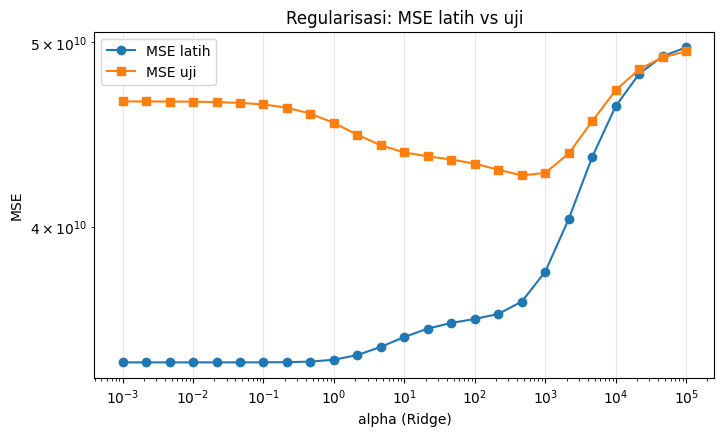

alpha dengan MSE uji terendah: 464 (MSE uji = 42565671706); alpha terkecil MSE uji = 46548769740


In [14]:
# [Tambahan] Bias-variance dalam praktik: error latih vs uji terhadap kekuatan regularisasi (Ridge) pada data berkolinear
# Fitur distandarisasi agar alpha lebih mudah dibandingkan; model dilatih ulang untuk tiap alpha.
from sklearn.pipeline import make_pipeline

alphas_r = np.logspace(-3, 5, 25)
tr_err, te_err = [], []
for a in alphas_r:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    tr_err.append(mean_squared_error(y_train, m.predict(X_train)))
    te_err.append(mean_squared_error(y_test, m.predict(X_test)))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(alphas_r, tr_err, "o-", label="MSE latih")
ax.plot(alphas_r, te_err, "s-", label="MSE uji")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("alpha (Ridge)"); ax.set_ylabel("MSE"); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_title("Regularisasi: MSE latih vs uji")
plt.show()
best_i = int(np.argmin(te_err))
print(f"alpha dengan MSE uji terendah: {alphas_r[best_i]:.3g} (MSE uji = {te_err[best_i]:.0f}); alpha terkecil MSE uji = {te_err[0]:.0f}")

**Interpretasi:** gambar ini adalah ilustrasi klasik *bias-variance trade-off*. Pada alpha kecil (≈ OLS), MSE latih (sekitar 3,3×10¹⁰) jauh lebih kecil daripada MSE uji (sekitar 4,7×10¹⁰): kesenjangan besar ini tanda **overfitting** (100 fitur yang saling berkorelasi untuk hanya 800 sampel latih → variansi tinggi). Saat alpha naik, MSE latih naik (bias bertambah) sedangkan MSE uji turun, mencapai minimum di sekitar **alpha ≈ 464** (MSE uji ≈ 4,26×10¹⁰, sekitar 8,6% lebih rendah daripada alpha terkecil). Setelah itu keduanya naik dan saling mendekat: **underfitting**, yaitu model terlalu dibatasi. Alpha optimal berada di antara dua ekstrem itu, dan mencarinya adalah tugas cross-validation (misalnya `RidgeCV`).

## 5. Regression and Regularization: Polynomial Regression dan Spline
Dua teknik yang memperluas regresi linear untuk hubungan **non-linear** (eksponensial atau melengkung). Keduanya tetap model *linear dalam koefisien*; yang diubah adalah fitur masukan.

### Getting ready: dataset non-linear
Satu fitur $x\in[-50, 50]$, target $y = 2x + 27\sin(x/8) + \text{noise}$: komponen linear ditambah gelombang sinus.

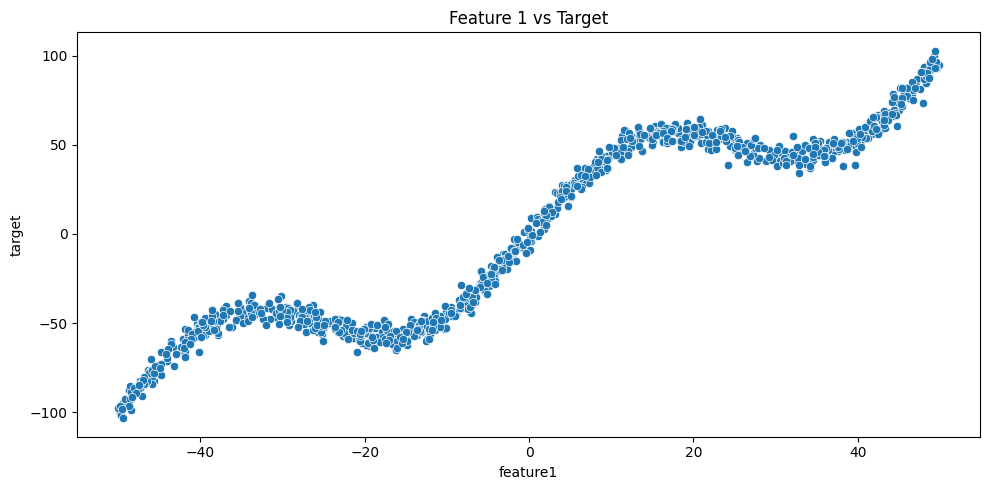

In [15]:
# [Dari buku] Dataset dengan komponen non-linear (gelombang sinus)
import seaborn as sns

np.random.seed(123)
n_samples = 1000
X = np.random.uniform(-50, 50, (n_samples, 1))
y = (2 * X[:, 0]                     # komponen linear
     + 27 * np.sin(X[:, 0] / 8)      # komponen non-linear
     + np.random.normal(0, 4, n_samples))   # noise

data = pd.DataFrame(X, columns=["feature1"])
data["target"] = y

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x="feature1", y="target")
plt.title("Feature 1 vs Target")
plt.tight_layout()
plt.show()

### 5a. Polynomial regression — How to do it…
`PolynomialFeatures(degree=d)` mengubah $x$ menjadi $[1, x, x^2, \dots, x^d]$, lalu `LinearRegression` dipasang pada fitur-fitur itu. Dicoba derajat 1 sampai 5.

In [16]:
# [Dari buku] Polynomial regression derajat 1-5
from sklearn.preprocessing import PolynomialFeatures

X = data[["feature1"]]
y = data["target"]

degrees = [1, 2, 3, 4, 5]
results = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=123)

    poly_model = LinearRegression()
    poly_model.fit(X_train, y_train)
    y_pred = poly_model.predict(X_test)

    results.append({"Degree": degree, "MSE": mean_squared_error(y_test, y_pred), "R2": r2_score(y_test, y_pred)})

results_df = pd.DataFrame(results)
print("\nModel Performance Metrics:")
print(results_df.to_string(index=False))


Model Performance Metrics:
 Degree        MSE       R2
      1 317.005037 0.891135
      2 316.818454 0.891199
      3 268.477397 0.907800
      4 268.230101 0.907885
      5  48.316167 0.983407


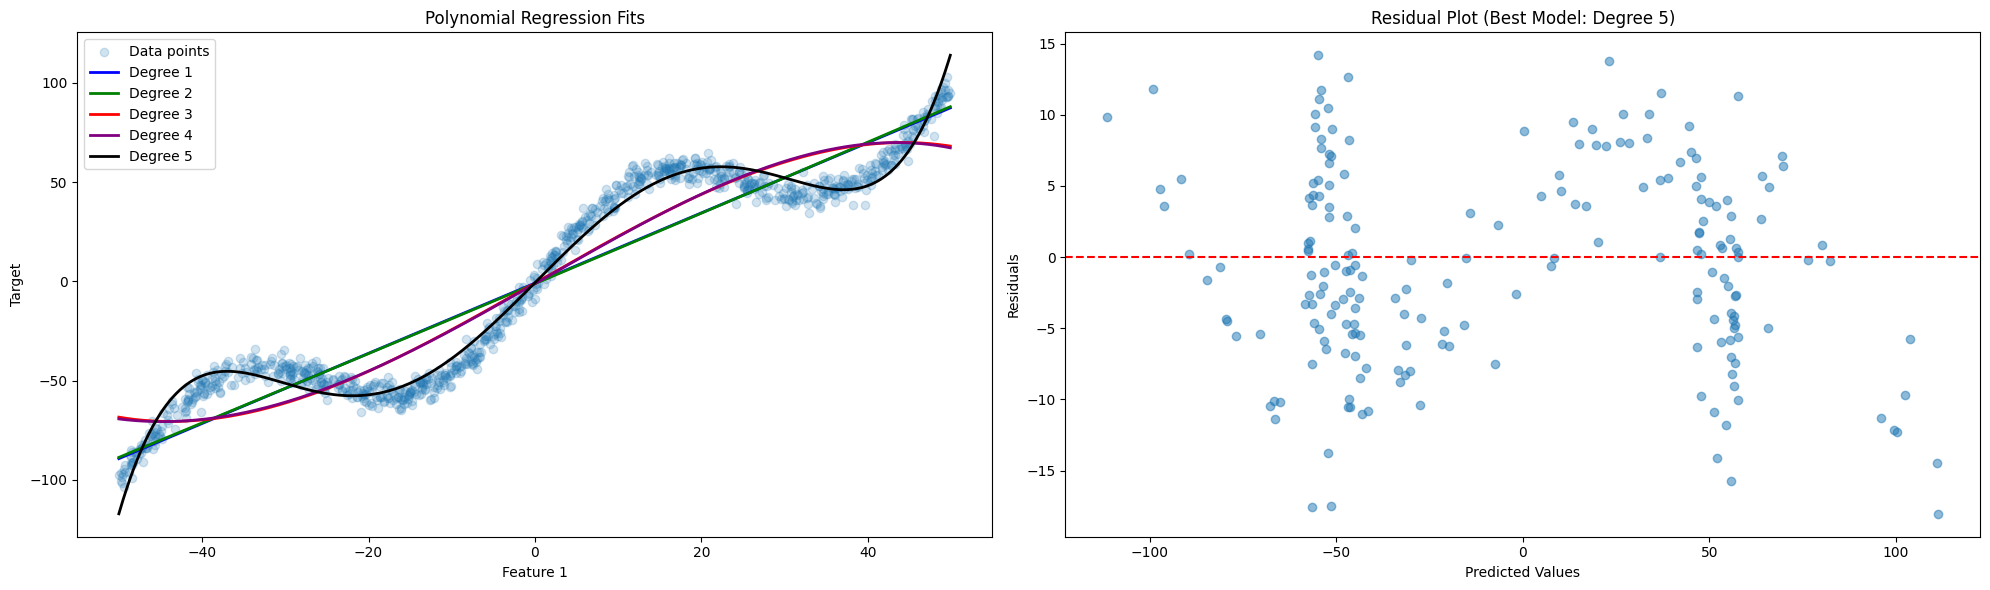

In [17]:
# [Dari buku] Visualisasi fit tiap derajat + residual plot model terbaik (berdasarkan R2)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))
ax1.scatter(X["feature1"], y, alpha=0.2, label="Data points")

X_plot = np.linspace(X["feature1"].min(), X["feature1"].max(), 1000).reshape(-1, 1)
colors = ["blue", "green", "red", "purple", "black"]

for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree)
    X_plot_poly = poly.fit_transform(X_plot)
    model = LinearRegression()
    model.fit(poly.fit_transform(X), y)
    ax1.plot(X_plot, model.predict(X_plot_poly), label=f"Degree {degree}", color=color, linewidth=2)

ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Target")
ax1.set_title("Polynomial Regression Fits")
ax1.legend(loc="upper left")

best_degree = results_df.loc[results_df["R2"].idxmax(), "Degree"]
best_poly = PolynomialFeatures(degree=best_degree)
X_poly_best = best_poly.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_poly_best, y, test_size=0.2, random_state=123)
best_model = LinearRegression()
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)
residuals = y_test - y_pred

ax2.scatter(y_pred, residuals, alpha=0.5)
ax2.axhline(y=0, color="r", linestyle="--")
ax2.set_xlabel("Predicted Values")
ax2.set_ylabel("Residuals")
ax2.set_title(f"Residual Plot (Best Model: Degree {best_degree})")
plt.tight_layout()
plt.show()

**Hasil:** derajat 1–2: MSE ≈ 317 (R² 0,891); derajat 3–4: ≈ 268 (R² 0,908); derajat 5: ≈ 48,3 (R² 0,983). Model terbaik menurut R² adalah derajat 5, sama dengan keterangan buku (Figure 5.8). Pola berundak (1≈2, 3≈4) muncul karena $\sin$ adalah fungsi **ganjil**: suku genap ($x^2$, $x^4$) hampir tidak membantu, hanya suku ganjil ($x$, $x^3$, $x^5$, …) yang mendekati bentuk sinus. Plot residual (kanan) dipakai untuk memeriksa apakah galat tersebar acak di sekitar 0; sisa pola menandakan struktur yang belum tertangkap.

**Peringatan overfitting (dari buku):** polinomial derajat tinggi bisa "tampak ajaib", tetapi berisiko menangkap noise. Memilih model hanya dari MSE/R² pada satu split bisa menyesatkan. Buku juga agak tidak konsisten: menyebut model terbaik adalah yang MSE-nya terendah, padahal kode memilih berdasarkan R² tertinggi (pada data uji yang sama keduanya selalu sepakat, karena R² adalah transformasi monoton dari MSE).

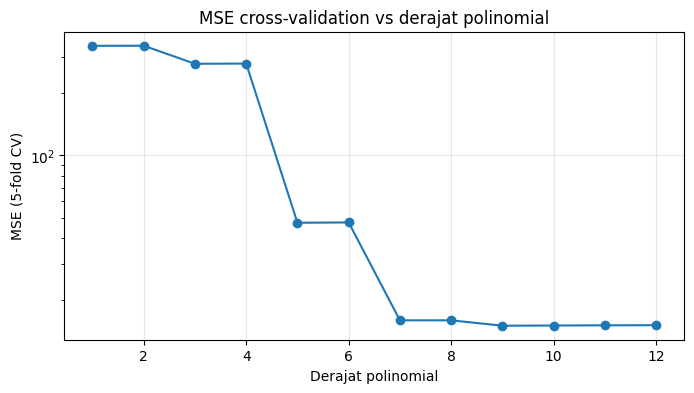

,Degree,CV MSE
0,1,338.33
1,2,338.73
2,3,277.16
3,4,277.75
4,5,47.33
5,6,47.50
6,7,16.00
7,8,16.00
8,9,15.07
9,10,15.10


Derajat dengan CV MSE terendah: 9


In [18]:
# [Tambahan] Cek overfitting dengan cross-validation (bukan hanya satu split) untuk derajat 1 sampai 12
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

deg_range = list(range(1, 13))
cv_rows = []
for d in deg_range:
    pipe = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), StandardScaler(), LinearRegression())
    s = cross_val_score(pipe, X, y, cv=5, scoring="neg_mean_squared_error")
    cv_rows.append({"Degree": d, "CV MSE": -s.mean()})
cv_df = pd.DataFrame(cv_rows)

plt.figure(figsize=(8, 4))
plt.plot(cv_df["Degree"], cv_df["CV MSE"], "o-")
plt.yscale("log"); plt.xlabel("Derajat polinomial"); plt.ylabel("MSE (5-fold CV)")
plt.title("MSE cross-validation vs derajat polinomial"); plt.grid(True, alpha=0.3); plt.show()
display(cv_df.round(2))
print("Derajat dengan CV MSE terendah:", int(cv_df.loc[cv_df['CV MSE'].idxmin(), 'Degree']))

**Interpretasi:** kurva berbentuk tangga (1≈2, 3≈4, 5≈6, 7≈8) karena $\sin$ fungsi ganjil. MSE-CV turun dari ≈ 338 (derajat 1–2) ke ≈ 277 (derajat 3–4), ≈ 47 (derajat 5–6), dan ≈ 16,0 (derajat 7–8), lalu **mendatar** di ≈ 15,1 pada derajat 9–12; nilai terendah ada di derajat 9 (≈ 15,07) tetapi selisihnya dengan derajat 10–12 hanya sekitar 0,1. Tidak ada tanda overfitting sampai derajat 12 pada data ini (1000 sampel, 1 fitur). Nilai ≈ 15–16 hampir sama dengan variansi noise yang ditambahkan ($4^2$), yaitu batas terbaik yang mungkin dicapai. Artinya derajat 5 yang dipilih dari tabel buku (MSE ≈ 47–48) sebenarnya masih *underfit*; derajat 7 atau lebih sudah mendekati batas noise, dan derajat yang lebih tinggi lagi tidak memberi manfaat berarti.

### How it works…
Polynomial regression memperluas regresi linear dengan memasang persamaan polinomial:
$$y = \beta_0 + \beta_1 x + \beta_2 x^2 + \cdots + \beta_d x^d + \epsilon$$
Dengan mentransformasi $x$ menjadi suku-suku polinomial, model dapat menangkap hubungan non-linear antara variabel dependen dan independen, sementara pemasangan koefisien tetap linear.

### 5b. Spline interpolation (`SplineTransformer`)
**Spline** menyusun kurva mulus dari potongan-potongan polinomial. Data dibagi menjadi segmen pada titik-titik yang disebut **knot**, tiap segmen dipasangi polinomial berderajat tertentu, dan hasilnya kontinu serta mulus di sambungan. `SplineTransformer` (di `sklearn.preprocessing`) memungkinkan mengatur jumlah knot dan derajat polinomial.

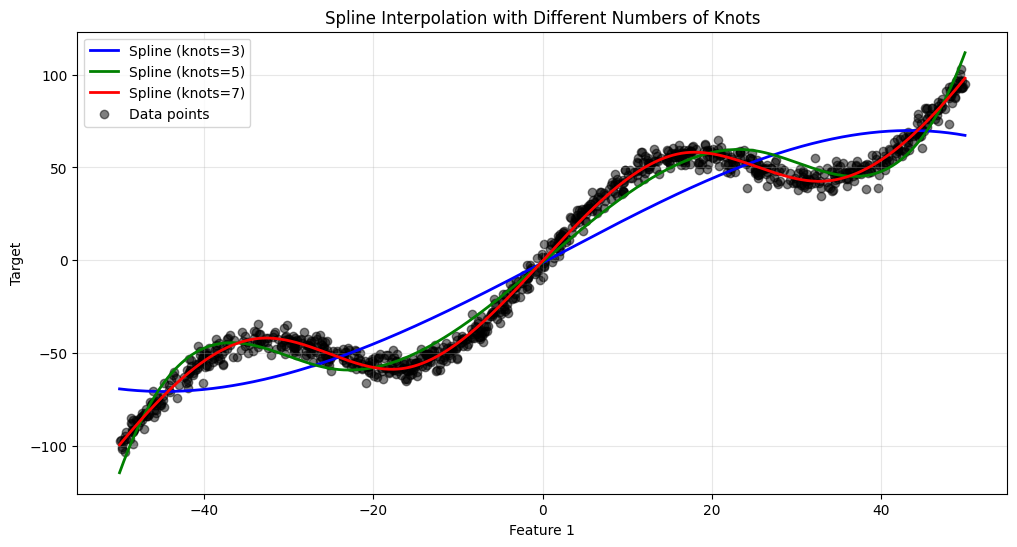

In [19]:
# [Dari buku] SplineTransformer dengan beberapa jumlah knot
# Catatan: X_plot diubah ke DataFrame bernama kolom 'feature1' agar sama dengan data latih (menghindari warning nama fitur).
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline

n_knots = [3, 5, 7]
plt.figure(figsize=(12, 6))

mse_scores = []
r2_scores = []
X_plot_df = pd.DataFrame(X_plot, columns=["feature1"])

for n_knot, color in zip(n_knots, colors[:len(n_knots)]):
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X, y)

    y_pred_plot = model.predict(X_plot_df)
    y_pred_train = model.predict(X)

    mse_scores.append(mean_squared_error(y, y_pred_train))
    r2_scores.append(r2_score(y, y_pred_train))

    plt.plot(X_plot, y_pred_plot, label=f"Spline (knots={n_knot})", color=color, linewidth=2)

plt.scatter(X, y, color="black", alpha=0.5, label="Data points")
plt.xlabel("Feature 1")
plt.ylabel("Target")
plt.title("Spline Interpolation with Different Numbers of Knots")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
# [Dari buku] Tabel metrik spline (dihitung pada DATA LATIH, seperti di buku)
metrics_spline_df = pd.DataFrame({"Number of Knots": n_knots, "MSE": mse_scores, "R-squared": r2_scores})
display(metrics_spline_df)

,Number of Knots,MSE,R-squared
0,3,274.267019,0.904652
1,5,55.347798,0.980759
2,7,15.502097,0.994611


In [21]:
# [Tambahan] Evaluasi spline pada DATA UJI (held-out) dan lebih banyak knot,
# karena metrik pada data latih selalu membaik saat knot bertambah dan tidak membuktikan generalisasi.
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X, y, test_size=0.2, random_state=123)
rows = []
for k in [3, 5, 7, 10, 15, 25, 40]:
    m = make_pipeline(SplineTransformer(n_knots=k, degree=3), LinearRegression()).fit(Xs_tr, ys_tr)
    rows.append({"Knots": k,
                 "MSE latih": mean_squared_error(ys_tr, m.predict(Xs_tr)),
                 "MSE uji": mean_squared_error(ys_te, m.predict(Xs_te))})
display(pd.DataFrame(rows).round(3))

,Knots,MSE latih,MSE uji
0,3,276.043,268.140
1,5,55.047,57.174
2,7,15.383,16.254
3,10,14.695,15.224
4,15,14.582,15.438
5,25,14.424,15.505
6,40,14.255,15.912


**Interpretasi:** pada data latih (tabel buku), MSE turun seiring bertambahnya knot. Itu **wajar dan tidak bisa dijadikan bukti** model lebih baik, sebab model lebih fleksibel selalu bisa lebih cocok dengan data latih. Angka tabel buku (Figure 5.10: 274,19; 55,36; 15,50) cocok dengan hasil saya (274,27; 55,35; 15,50). Tabel tambahan membandingkan MSE latih vs uji: MSE uji terendah pada 10 knot (≈ 15,2), lalu sedikit naik (≈ 15,4 → 15,5 → 15,9 pada 15/25/40 knot) sementara MSE latih terus turun (≈ 14,7 → 14,3), tanda ringan mulai menyesuaikan noise. Perhatikan juga bahwa noise sebenarnya pada data ini memiliki simpangan baku 4 (variansi ≈ 16), jadi MSE yang mendekati ≈16 sudah mendekati batas terbaik yang mungkin dicapai.

### How it works…
Spline interpolation adalah metode fleksibel yang memasang **polinomial piecewise** pada titik data: transisi antar segmen mulus dan kontinuitas dijaga di batas segmen. Berguna untuk data kompleks dengan tren non-linear. Dibandingkan polinomial derajat tinggi tunggal, spline lebih stabil karena tiap segmen hanya berderajat rendah (pada kode ini derajat 3, yaitu *cubic spline*), sehingga mengurangi osilasi liar di tepi data.

### There's more…
Untuk pemodelan non-linear yang lebih canggih, buku menyarankan mengeksplorasi *B-splines* atau *natural splines*. (`SplineTransformer` di scikit-learn sendiri membangun basis B-spline.)

## Kesimpulan Chapter 5
- **Regresi linear (OLS)** memodelkan target sebagai kombinasi linear fitur dan dievaluasi dengan **MSE** dan **R²**.
- **Ridge (L2)** menyusutkan koefisien tanpa menjadikannya 0; **Lasso (L1)** dapat menjadikan koefisien tepat 0 (seleksi fitur); **ElasticNet** menggabungkan keduanya lewat `alpha` dan `l1_ratio`, dan cocok untuk fitur berkorelasi.
- **Regularisasi** menukar sedikit bias dengan penurunan variansi (bias-variance trade-off) agar model menggeneralisasi lebih baik. Kekuatannya (alpha) harus dipilih lewat validasi, bukan ditebak.
- **Polynomial regression** dan **spline** memperluas model linear ke pola non-linear dengan mengubah fitur. Polinomial derajat tinggi berisiko overfitting, sedangkan spline lebih stabil karena potongan berderajat rendah.
- Evaluasi harus pada **data uji atau cross-validation**: metrik pada data latih selalu membaik saat model lebih kompleks dan tidak menjamin generalisasi.